# YOLOv11 untuk Deteksi Kematangan Buah Sawit — Baseline & Fine-tuning

Notebook ini mendokumentasikan instalasi, pembagian data, pelatihan baseline, fine-tuning, evaluasi, analisis error, dan penyimpanan model YOLOv11 untuk membandingkan YOLOv11 dengan Faster R-CNN (FGD Kelompok 2).

**Protokol (sengaja disamakan dengan notebook Faster R-CNN agar perbandingannya adil):**

1. Baseline dilatih **20 epoch**; checkpoint terbaik dipilih dari split **validasi**.
2. Fine-tuning **melanjutkan dari checkpoint baseline terbaik** dengan learning rate lebih kecil, maksimum 10 epoch, dan *early stopping* 5 epoch.
3. Split **test** tidak dipakai untuk memilih checkpoint, epoch, atau hyperparameter. Test hanya dipakai untuk evaluasi akhir.
4. Selain metrik Ultralytics, mAP juga dihitung dengan **pycocotools** pada anotasi COCO yang sama dengan Faster R-CNN, supaya definisi metriknya setara.

**Sebelum mulai:** Settings → Accelerator → **GPU T4 x2**, dan aktifkan **Internet**.

## Tahap 1 — Instalasi Dependensi

`ultralytics` menyediakan YOLOv11, sedangkan `pycocotools` menghitung metrik COCO (mAP@[0.50:0.95], mAP@0.50, mAP@0.75) seperti pada notebook Faster R-CNN.

In [1]:
!pip install -q ultralytics pycocotools

## Tahap 2 — Inisialisasi Library, Seed, dan Perangkat Komputasi

Seed ditetapkan agar eksperimen dapat diulang. Perangkat harus `cuda` (GPU); jika `cpu`, pelatihan akan sangat lambat.

In [2]:
import json, random, time, shutil, hashlib, datetime, os, zipfile
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import ultralytics
import yaml
from ultralytics import YOLO

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
GPU_NAME = torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU"
print("Ultralytics :", ultralytics.__version__)
print("PyTorch     :", torch.__version__)
print("Device      :", DEVICE, "-", GPU_NAME)
if DEVICE != "cuda":
    print("PERINGATAN: GPU tidak aktif. Nyalakan GPU di Settings → Accelerator.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics : 8.4.193
PyTorch     : 2.11.0+cu128
Device      : cuda - Tesla T4


**Cara membaca output:** `Device: cuda - Tesla T4` berarti GPU aktif. Catat versi Ultralytics dan PyTorch untuk laporan (aturan 7.3 dokumen handoff).

## Tahap 3 — Pengambilan Data

Ada dua sumber, digabung di sini:
- **Label dan YAML** dari output notebook *FGD DGX Preprocessing* (Add Input). Labelnya sudah dalam format bbox.
- **Gambar** diunduh dari Roboflow memakai API key kamu, karena gambar di output Kak Moreno berupa link yang rusak di Kaggle.

Sel terakhir memastikan setiap label punya gambar pasangannya. Angka harus sama dengan dokumen handoff.

In [3]:
%pip install -q roboflow
from kaggle_secrets import UserSecretsClient
from pathlib import Path
from roboflow import Roboflow

RF_DIR = Path("/kaggle/working/palm-oil-3")
if not (RF_DIR / "train" / "images").exists():
    api_key = UserSecretsClient().get_secret("ROBOFLOW_API_KEY")
    rf = Roboflow(api_key=api_key)
    ds = rf.workspace("zah").project("palm-oil-fg85a").version(3).download(
        "yolov11", location=str(RF_DIR))
    print("Unduhan selesai:", ds.location)
else:
    print("Gambar Roboflow sudah ada, unduhan dilewati:", RF_DIR)

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
Note: you may need to restart the kernel to use updated packages.
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /kaggle/working/palm-oil-3 in yolov11:: 100%|██████████| 16804/16804 [00:02<00:00, 7842.69it/s]


Unduhan selesai: /kaggle/working/palm-oil-3


In [4]:
# KONFIGURASI 
LABEL_SRC      = Path("/kaggle/input/notebooks/morenoadryan/fgd-dgx-preprocessing/palm_oil_model_comparison/yolo_detection_ready")
COCO_TEST_JSON = "/kaggle/input/notebooks/morenoadryan/fgd-dgx-preprocessing/palm_oil_model_comparison/preprocessing_output/instances_test.json"
DATA_ROOT      = Path("/kaggle/working/data/yolo_detection_ready")

CEK_ANGKA_HANDOFF = True    # angka split sama dengan dokumen handoff (5.893 / 1.676 / 827)

OUT_DIR    = "/kaggle/working/FGD_Sawit_YOLOv11"   # tab Output setelah notebook selesai
MODEL_NAME = "yolo11s.pt"
IMGSZ      = 640
BATCH      = 16             # kalau error CUDA out of memory, turunkan ke 8
# =====================================================
os.makedirs(OUT_DIR, exist_ok=True)
print("Label dari :", LABEL_SRC)
print("COCO test  :", COCO_TEST_JSON, "| ada:", Path(COCO_TEST_JSON).exists())

Label dari : /kaggle/input/notebooks/morenoadryan/fgd-dgx-preprocessing/palm_oil_model_comparison/yolo_detection_ready
COCO test  : /kaggle/input/notebooks/morenoadryan/fgd-dgx-preprocessing/palm_oil_model_comparison/preprocessing_output/instances_test.json | ada: True


In [5]:
SPLIT_RF = {"train": "train", "val": "valid", "test": "test"}   # nama split di Roboflow

if DATA_ROOT.parent.exists():
    shutil.rmtree(DATA_ROOT.parent)
DATA_ROOT.mkdir(parents=True)
shutil.copy2(LABEL_SRC / "data_yolo_detection_ready.yaml", DATA_ROOT / "data_yolo_detection_ready.yaml")

for m, r in SPLIT_RF.items():
    img_src = RF_DIR / r / "images"
    img_dst = DATA_ROOT / m / "images"
    img_dst.mkdir(parents=True, exist_ok=True)
    shutil.copytree(LABEL_SRC / m / "labels", DATA_ROOT / m / "labels")

    n, missing = 0, []
    for lbl in sorted((LABEL_SRC / m / "labels").glob("*.txt")):
        img = next((img_src / (lbl.stem + e) for e in [".jpg", ".jpeg", ".png"]
                    if (img_src / (lbl.stem + e)).exists()), None)
        if img is None:
            missing.append(lbl.name)
            continue
        shutil.copy2(img, img_dst / img.name)
        n += 1
    print(f"{m:5s} gambar={n} label_tanpa_gambar={len(missing)}")
    assert not missing, f"Gambar tidak ditemukan untuk: {missing[:3]}"

print("Folder dataset :", DATA_ROOT)

train gambar=5893 label_tanpa_gambar=0
val   gambar=1676 label_tanpa_gambar=0
test  gambar=827 label_tanpa_gambar=0
Folder dataset : /kaggle/working/data/yolo_detection_ready


## Tahap 4 — Pembagian Data (Split) dan Validasi Integritas

Dokumen handoff mengunci split **train / validasi / test** dan melarang *re-split*. Tahap ini membuktikan bahwa data yang dipakai benar-benar sama dengan split tersebut:

- jumlah gambar, label, dan bounding box per split;
- sebaran kelas per split;
- setiap gambar punya file label (dan sebaliknya), ID kelas valid (0–3), koordinat bbox ternormalisasi;
- tidak ada gambar identik (hash MD5) yang muncul di lebih dari satu split.

`gambar_tanpa_objek` adalah gambar *background* (tanpa tandan); jumlahnya wajar dan ikut dilatih sebagai contoh negatif.

In [6]:
CLASS_NAMES = {0: "kurang masak", 1: "masak", 2: "mentah", 3: "terlalu masak"}
SPLITS = ["train", "val", "test"]

# Angka acuan dari dokumen handoff
EXPECTED_IMAGES = {"train": 5893, "val": 1676, "test": 827}
EXPECTED_BOXES  = {"train": 9266, "val": 2654, "test": 1355}
EXPECTED_CLASS  = {   # kelas: (train, val, test)
    0: (2635, 757, 394),
    1: (1959, 556, 271),
    2: (2447, 705, 362),
    3: (2225, 636, 328),
}
IMG_EXT = {".jpg", ".jpeg", ".png"}

def audit_split(split):
    img_dir = DATA_ROOT / split / "images"
    lbl_dir = DATA_ROOT / split / "labels"
    imgs = {p.stem: p for p in img_dir.iterdir() if p.suffix.lower() in IMG_EXT}
    lbls = {p.stem: p for p in lbl_dir.glob("*.txt")}
    class_count, n_boxes, n_empty = Counter(), 0, 0
    bad_line, bad_class, bad_range = 0, 0, 0
    for stem, p in lbls.items():
        rows = [l.split() for l in p.read_text().splitlines() if l.strip()]
        if not rows:
            n_empty += 1
        for tok in rows:
            if len(tok) != 5:
                bad_line += 1
                continue
            c = int(float(tok[0]))
            x, y, w, h = map(float, tok[1:])
            if c not in CLASS_NAMES:
                bad_class += 1
                continue
            if not (0 <= x <= 1 and 0 <= y <= 1 and 0 < w <= 1 and 0 < h <= 1):
                bad_range += 1
            class_count[c] += 1
            n_boxes += 1
    row = {
        "split": split, "gambar": len(imgs), "label": len(lbls),
        "tanpa_pasangan": len(set(imgs) ^ set(lbls)),
        "gambar_tanpa_objek": n_empty, "bbox": n_boxes,
        "baris_bukan_bbox": bad_line, "kelas_tidak_valid": bad_class, "bbox_luar_rentang": bad_range,
    }
    return row, class_count, imgs

audit_rows, class_counts, image_maps = [], {}, {}
for s in SPLITS:
    row, cc, imgs = audit_split(s)
    audit_rows.append(row); class_counts[s] = cc; image_maps[s] = imgs

audit = pd.DataFrame(audit_rows).set_index("split")
audit["sesuai_handoff"] = [
    (audit.loc[s, "gambar"] == EXPECTED_IMAGES[s]) and (audit.loc[s, "bbox"] == EXPECTED_BOXES[s]) for s in SPLITS
]
display(audit)

dist = pd.DataFrame(
    {s: [class_counts[s][c] for c in CLASS_NAMES] for s in SPLITS},
    index=[CLASS_NAMES[c] for c in CLASS_NAMES],
)
dist["sesuai_handoff"] = [
    tuple(dist.iloc[i][SPLITS]) == EXPECTED_CLASS[i] for i in range(len(CLASS_NAMES))
]
display(dist)

problem_cols = ["tanpa_pasangan", "baris_bukan_bbox", "kelas_tidak_valid", "bbox_luar_rentang"]
ok = bool((audit[problem_cols] == 0).all().all())
if CEK_ANGKA_HANDOFF:
    ok = ok and bool(audit["sesuai_handoff"].all() and dist["sesuai_handoff"].all())
print("\nSEMUA OK, data sesuai dokumen handoff." if ok else "\nADA YANG TIDAK COCOK. Jangan training dulu, tanyakan ke temanmu.")

,gambar,label,tanpa_pasangan,gambar_tanpa_objek,bbox,baris_bukan_bbox,kelas_tidak_valid,bbox_luar_rentang,sesuai_handoff
split,,,,,,,,,
train,5893,5893,0,1282,9266,0,0,0,True
val,1676,1676,0,366,2654,0,0,0,True
test,827,827,0,173,1355,0,0,0,True


,train,val,test,sesuai_handoff
kurang masak,2635,757,394,True
masak,1959,556,271,True
mentah,2447,705,362,True
terlalu masak,2225,636,328,True



SEMUA OK, data sesuai dokumen handoff.


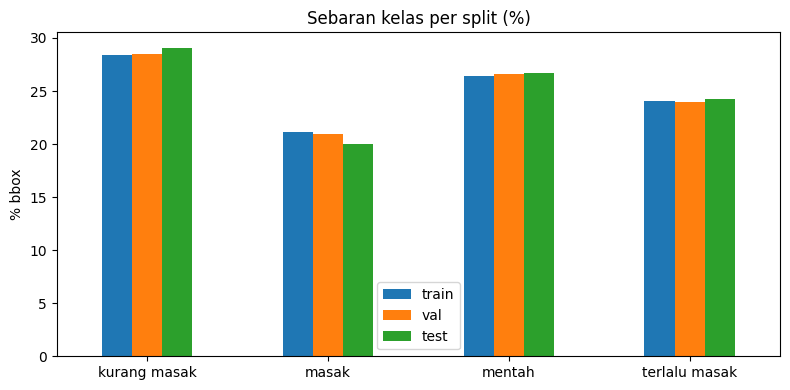

In [7]:
# Visualisasi sebaran kelas per split (dalam persen)
pct = dist[SPLITS].div(dist[SPLITS].sum(axis=0), axis=1) * 100
ax = pct.plot(kind="bar", figsize=(8, 4))
ax.set(title="Sebaran kelas per split (%)", ylabel="% bbox", xlabel="")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

In [8]:
# Cek duplikat identik lintas split (hash MD5)
def md5(path, chunk=1 << 20):
    h = hashlib.md5()
    with open(path, "rb") as f:
        while True:
            b = f.read(chunk)
            if not b:
                break
            h.update(b)
    return h.hexdigest()

hashes = {s: {md5(p) for p in image_maps[s].values()} for s in SPLITS}
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    print(f"Duplikat identik {a} vs {b}: {len(hashes[a] & hashes[b])}")

Duplikat identik train vs val: 0
Duplikat identik train vs test: 0
Duplikat identik val vs test: 0


**Cara membaca output:** semua kolom `sesuai_handoff` harus `True` dan kolom masalah harus `0`. Jumlah duplikat identik harus 0. Catatan: pemeriksaan hash hanya mendeteksi duplikat yang identik persis; frame video yang sangat mirip tetap bisa lolos (sudah dicatat sebagai keterbatasan di dokumen handoff).

In [9]:
# Perbarui 'path' di YAML ke lokasi data di Colab, simpan sebagai file baru (YAML asli tidak diubah)
with open(DATA_ROOT / "data_yolo_detection_ready.yaml", encoding="utf-8") as f:
    cfg = yaml.safe_load(f)

cfg["path"], cfg["train"], cfg["val"], cfg["test"] = str(DATA_ROOT), "train/images", "val/images", "test/images"

DATA_YAML = "/kaggle/working/data_colab.yaml"
with open(DATA_YAML, "w", encoding="utf-8") as f:
    yaml.safe_dump(cfg, f, allow_unicode=True, sort_keys=False)

print(open(DATA_YAML, encoding="utf-8").read())
assert cfg["nc"] == 4, "Jumlah kelas harus 4"

path: /kaggle/working/data/yolo_detection_ready
train: train/images
val: val/images
test: test/images
nc: 4
names:
- kurang masak
- masak
- mentah
- terlalu masak



## Tahap 5 — Definisi Kelas dan Konfigurasi Eksperimen

YOLOv11 memakai ID kelas 0–3, sedangkan format COCO/Faster R-CNN memakai 1–4 (ID 0 dicadangkan untuk *background*). Mapping ini wajib konsisten agar hasil kedua model bisa dibandingkan.

Hyperparameter baseline dan fine-tuning dikumpulkan di satu tempat supaya mudah dilaporkan:

- **Baseline:** bobot pralatih `yolo11s.pt`, 20 epoch. Ultralytics mematikan augmentasi *mosaic* pada 10 epoch terakhir (`close_mosaic=10`, bawaan).
- **Fine-tuning:** dimulai dari checkpoint baseline terbaik (bukan dari bobot awal), optimizer SGD baru dengan learning rate `1e-4`, maksimum 10 epoch, *early stopping* 5 epoch. Dengan 10 epoch, mosaic otomatis mati sejak awal sehingga fine-tuning memakai gambar apa adanya.

In [10]:
COCO_ID = {c: c + 1 for c in CLASS_NAMES}   # YOLO id -> COCO id
display(pd.DataFrame({
    "kelas": list(CLASS_NAMES.values()),
    "ID YOLOv11": list(CLASS_NAMES.keys()),
    "ID COCO / Faster R-CNN": [COCO_ID[c] for c in CLASS_NAMES],
}))

BASELINE = dict(epochs=20, patience=20, run_name="yolo11s_baseline20")
FINETUNE = dict(epochs=10, patience=5, lr0=1e-4, lrf=0.1, momentum=0.9, optimizer="SGD",
                run_name="yolo11s_finetune")

BASE_DIR  = Path(OUT_DIR) / BASELINE["run_name"]
FT_DIR    = Path(OUT_DIR) / FINETUNE["run_name"]
BASE_BEST = BASE_DIR / "weights" / "best.pt"
FT_BEST   = FT_DIR / "weights" / "best.pt"

TRAIN_SECONDS = {}   # diisi otomatis saat training
RESULTS = {}         # diisi saat evaluasi
print("Baseline :", BASELINE)
print("Fine-tune:", FINETUNE)

,kelas,ID YOLOv11,ID COCO / Faster R-CNN
0,kurang masak,0,1
1,masak,1,2
2,mentah,2,3
3,terlalu masak,3,4


Baseline : {'epochs': 20, 'patience': 20, 'run_name': 'yolo11s_baseline20'}
Fine-tune: {'epochs': 10, 'patience': 5, 'lr0': 0.0001, 'lrf': 0.1, 'momentum': 0.9, 'optimizer': 'SGD', 'run_name': 'yolo11s_finetune'}


## Tahap 6 — Pelatihan Baseline (20 Epoch)

Model dilatih dari bobot pralatih. Data **val** dipakai tiap epoch untuk memantau kemajuan; data **test tidak disentuh**. Ultralytics menyimpan `best.pt` berdasarkan metrik validasi (kombinasi mAP@0.5 dan mAP@0.5:0.95), dan hasilnya ditulis langsung ke Kaggle Input.

In [11]:
t0 = time.time()
model = YOLO(MODEL_NAME)
model.train(
    data=DATA_YAML,
    epochs=BASELINE["epochs"],
    imgsz=IMGSZ,
    batch=BATCH,
    seed=SEED,
    deterministic=True,
    patience=BASELINE["patience"],
    project=OUT_DIR,
    name=BASELINE["run_name"],
    exist_ok=True,
    save_period=5,
    plots=True,
    workers=2,
)
TRAIN_SECONDS["baseline"] = time.time() - t0
print(f"Waktu training baseline: {TRAIN_SECONDS['baseline']/3600:.2f} jam")

Ultralytics 8.4.193 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data_colab.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11s_baseline20, nbs=64, nms=None, opset=None, optimize=

`get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.


       2/20      5.05G      1.118      1.243      1.413         14        640: 100% ━━━━━━━━━━━━ 369/369 5.5it/s 1:07
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 53/53 4.5it/s 11.8s
                   all       1676       2653      0.652       0.75      0.765      0.486

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/20      5.05G      1.102      1.198      1.404         16        640: 100% ━━━━━━━━━━━━ 369/369 5.5it/s 1:08
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 53/53 4.6it/s 11.4s
                   all       1676       2653      0.446      0.614      0.595      0.388

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/20      5.05G      1.064      1.119      1.376         16        640: 100% ━━━━━━━━━━━━ 369/369 5.4it/s 1:09
                 Class     Images  Instances      Box(

### (Opsional) Lanjutkan baseline yang terputus

Kalau sesi Colab terputus: ulangi Tahap 1–5, lewati sel training di atas, lalu hapus tanda `#` di bawah dan jalankan.

In [12]:
# HANYA kalau training baseline terputus
# YOLO(str(BASE_DIR / "weights" / "last.pt")).train(resume=True)

## Tahap 7 — Learning Curve Baseline

Yang dicari: loss turun, lalu mAP validasi naik dan mendatar. Jika loss train terus turun tetapi mAP validasi turun, itu tanda *overfitting*.

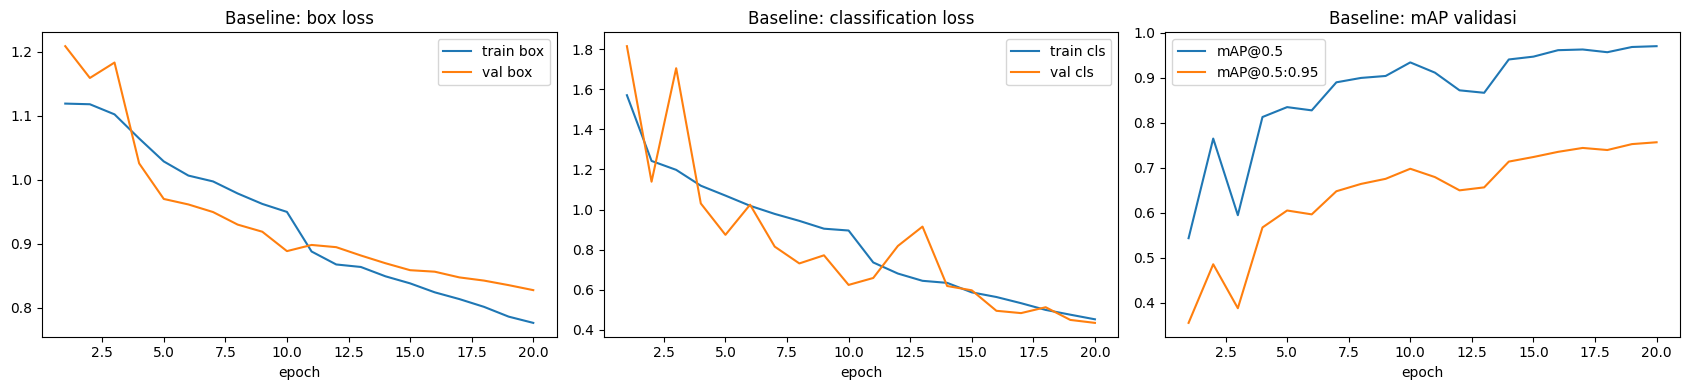

Epoch terbaik baseline (val mAP50-95): 20 dari 20


In [13]:
def load_log(run_dir):
    log = pd.read_csv(Path(run_dir) / "results.csv")
    log.columns = [c.strip() for c in log.columns]
    return log

def plot_curves(log, title):
    fig, ax = plt.subplots(1, 3, figsize=(17, 4))
    ax[0].plot(log["epoch"], log["train/box_loss"], label="train box")
    ax[0].plot(log["epoch"], log["val/box_loss"], label="val box")
    ax[0].set(title=f"{title}: box loss", xlabel="epoch"); ax[0].legend()
    ax[1].plot(log["epoch"], log["train/cls_loss"], label="train cls")
    ax[1].plot(log["epoch"], log["val/cls_loss"], label="val cls")
    ax[1].set(title=f"{title}: classification loss", xlabel="epoch"); ax[1].legend()
    ax[2].plot(log["epoch"], log["metrics/mAP50(B)"], label="mAP@0.5")
    ax[2].plot(log["epoch"], log["metrics/mAP50-95(B)"], label="mAP@0.5:0.95")
    ax[2].set(title=f"{title}: mAP validasi", xlabel="epoch"); ax[2].legend()
    plt.tight_layout(); plt.show()

base_log = load_log(BASE_DIR)
plot_curves(base_log, "Baseline")
base_best_epoch = int(base_log.loc[base_log["metrics/mAP50-95(B)"].idxmax(), "epoch"])
print("Epoch terbaik baseline (val mAP50-95):", base_best_epoch, "dari", int(base_log["epoch"].max()))

## Tahap 8 — Evaluasi Baseline

Checkpoint baseline terbaik dievaluasi pada validasi (untuk dicatat) dan pada **test** (hasil akhir baseline). Hasil test ini menjadi pembanding untuk fine-tuning. Fungsi `evaluate` dipakai ulang untuk model fine-tuned.

In [14]:
def evaluate(weights, split, tag, plots=False):
    m = YOLO(str(weights))
    res = m.val(data=DATA_YAML, split=split, imgsz=IMGSZ, batch=BATCH, plots=plots,
                verbose=False, project=OUT_DIR, name=f"{tag}_{split}", exist_ok=True)
    per_class = pd.DataFrame({
        "kelas": [m.names[i] for i in res.box.ap_class_index],
        "precision": res.box.p.round(4),
        "recall": res.box.r.round(4),
        "AP@0.5": res.box.ap50.round(4),
        "AP@0.5:0.95": res.box.ap.round(4),
    })
    return {
        "split": split,
        "precision": round(float(res.box.mp), 4),
        "recall": round(float(res.box.mr), 4),
        "mAP@0.5": round(float(res.box.map50), 4),
        "mAP@0.5:0.95": round(float(res.box.map), 4),
        "speed_ms": {k: round(float(v), 2) for k, v in res.speed.items()},
        "per_class": per_class,
    }

def ringkas(model_name):
    rows = []
    for split, r in RESULTS[model_name].items():
        if split in ("val", "test"):
            rows.append({"model": model_name, "split": split, **{k: r[k] for k in ["precision", "recall", "mAP@0.5", "mAP@0.5:0.95"]}})
    return pd.DataFrame(rows)

RESULTS["baseline"] = {
    "val":  evaluate(BASE_BEST, "val",  "baseline"),
    "test": evaluate(BASE_BEST, "test", "baseline"),
}
display(ringkas("baseline"))
display(RESULTS["baseline"]["test"]["per_class"])

Ultralytics 8.4.193 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 100 layers, 9,414,348 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2371.6±707.6 MB/s, size: 100.9 KB)
val: Scanning /kaggle/working/data/yolo_detection_ready/val/labels.cache... 1676 images, 366 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1676/1676 502.1Mit/s 0.0s
val: /kaggle/working/data/yolo_detection_ready/val/images/framesawit27-11-_png_jpg.rf.bbaffc3ea26ffc649d02bc21ebe0f5e0.jpg: 1 duplicate labels removed
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 105/105 4.9it/s 21.3s
                   all       1676       2653      0.901      0.947      0.971      0.757
Speed: 0.8ms preprocess, 9.8ms inference, 0.0ms loss, 0.7ms postprocess per image
Ultralytics 8.4.193 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 100 layers, 9,414,348 par

,model,split,precision,recall,mAP@0.5,mAP@0.5:0.95
0,baseline,val,0.9010,0.9474,0.9707,0.7566
1,baseline,test,0.9022,0.9494,0.9760,0.7584


,kelas,precision,recall,AP@0.5,AP@0.5:0.95
0,kurang masak,0.9053,0.8981,0.9694,0.7160
1,masak,0.9379,0.9479,0.9847,0.8241
2,mentah,0.8501,0.9641,0.9703,0.7420
3,terlalu masak,0.9152,0.9875,0.9795,0.7514


**Cara membaca output:** nilai val dan test yang berdekatan menandakan model tidak sekadar menghafal data validasi. `AP@0.5:0.95` per kelas menunjukkan kelas mana yang paling sulit (kotak kurang presisi).

## Tahap 9 — Fine-tuning dari Checkpoint Baseline

Fine-tuning **melanjutkan dari `best.pt` baseline**, bukan dari bobot awal. Optimizer baru dibuat (state optimizer lama tidak dilanjutkan), dengan learning rate lebih kecil daripada baseline. Pemilihan checkpoint tetap berdasarkan validasi, dan test tidak dipakai.

In [15]:
assert BASE_BEST.is_file(), f"Checkpoint baseline belum ada: {BASE_BEST}"
t0 = time.time()
ft_model = YOLO(str(BASE_BEST))
ft_model.train(
    data=DATA_YAML,
    epochs=FINETUNE["epochs"],
    imgsz=IMGSZ,
    batch=BATCH,
    seed=SEED,
    deterministic=True,
    patience=FINETUNE["patience"],
    optimizer=FINETUNE["optimizer"],
    lr0=FINETUNE["lr0"],
    lrf=FINETUNE["lrf"],
    momentum=FINETUNE["momentum"],
    warmup_epochs=0,
    project=OUT_DIR,
    name=FINETUNE["run_name"],
    exist_ok=True,
    plots=True,
    workers=2,
)
TRAIN_SECONDS["finetuned"] = time.time() - t0
print(f"Waktu fine-tuning: {TRAIN_SECONDS['finetuned']/3600:.2f} jam")

Ultralytics 8.4.193 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data_colab.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.1, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/kaggle/working/FGD_Sawit_YOLOv11/yolo11s_baseline20/weights/best.pt, momentum=0.9, mosaic=1.0, multi_scale=0.0, name=yo

## Tahap 10 — Perbandingan Baseline dan Fine-tuning pada Validasi

Grafik menyambung epoch baseline (1–20) dengan epoch fine-tuning (21 dst.). Setelah itu, keputusan apakah fine-tuning benar-benar membantu diambil dari **validasi**, bukan dari test.

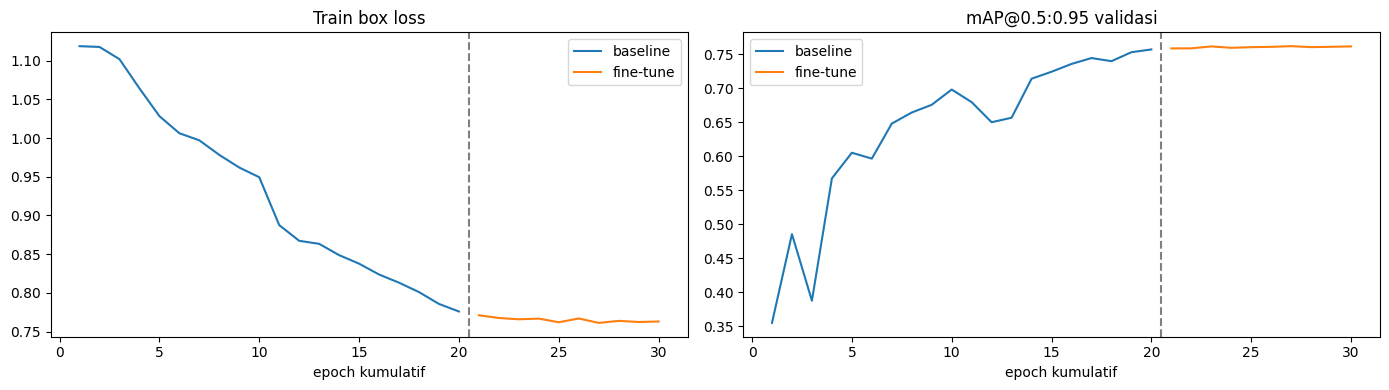

Epoch terbaik fine-tune (val mAP50-95): 7 dari 10 epoch fine-tune


In [16]:
ft_log = load_log(FT_DIR)
offset = int(base_log["epoch"].max())
ft_x = ft_log["epoch"] + offset

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(base_log["epoch"], base_log["train/box_loss"], label="baseline")
ax[0].plot(ft_x, ft_log["train/box_loss"], label="fine-tune")
ax[0].axvline(offset + 0.5, color="gray", ls="--"); ax[0].set(title="Train box loss", xlabel="epoch kumulatif"); ax[0].legend()
ax[1].plot(base_log["epoch"], base_log["metrics/mAP50-95(B)"], label="baseline")
ax[1].plot(ft_x, ft_log["metrics/mAP50-95(B)"], label="fine-tune")
ax[1].axvline(offset + 0.5, color="gray", ls="--"); ax[1].set(title="mAP@0.5:0.95 validasi", xlabel="epoch kumulatif"); ax[1].legend()
plt.tight_layout(); plt.show()

ft_best_epoch = int(ft_log.loc[ft_log["metrics/mAP50-95(B)"].idxmax(), "epoch"])
print("Epoch terbaik fine-tune (val mAP50-95):", ft_best_epoch, "dari", int(ft_log["epoch"].max()), "epoch fine-tune")

In [17]:
RESULTS["finetuned"] = {"val": evaluate(FT_BEST, "val", "finetuned")}
v_base = RESULTS["baseline"]["val"]["mAP@0.5:0.95"]
v_ft = RESULTS["finetuned"]["val"]["mAP@0.5:0.95"]
print(f"val mAP@0.5:0.95  baseline={v_base:.4f} | fine-tuned={v_ft:.4f} | selisih={v_ft - v_base:+.4f}")
print("Fine-tuning MENINGKATKAN mAP validasi." if v_ft > v_base else
      "Fine-tuning TIDAK meningkatkan mAP validasi. Laporkan apa adanya dan jelaskan di pembahasan.")

Ultralytics 8.4.193 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 100 layers, 9,414,348 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2116.2±647.7 MB/s, size: 100.9 KB)
val: Scanning /kaggle/working/data/yolo_detection_ready/val/labels.cache... 1676 images, 366 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1676/1676 502.1Mit/s 0.0s
val: /kaggle/working/data/yolo_detection_ready/val/images/framesawit27-11-_png_jpg.rf.bbaffc3ea26ffc649d02bc21ebe0f5e0.jpg: 1 duplicate labels removed
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 105/105 4.9it/s 21.4s
                   all       1676       2653      0.909      0.948      0.973      0.762
Speed: 0.9ms preprocess, 9.7ms inference, 0.0ms loss, 0.7ms postprocess per image
val mAP@0.5:0.95  baseline=0.7566 | fine-tuned=0.7615 | selisih=+0.0049
Fine-tuning MENINGKATKAN mAP validasi.


## Tahap 11 — Evaluasi Akhir pada Split Test

> Jalankan bagian ini **sekali saja**, setelah pelatihan selesai. Sesuai aturan dokumen handoff, test tidak boleh dipakai untuk memilih epoch, ambang kepercayaan, atau hyperparameter.

In [18]:
RESULTS["finetuned"]["test"] = evaluate(FT_BEST, "test", "finetuned", plots=True)

tabel = pd.concat([ringkas("baseline"), ringkas("finetuned")], ignore_index=True)
display(tabel)

pc = RESULTS["baseline"]["test"]["per_class"].merge(
    RESULTS["finetuned"]["test"]["per_class"], on="kelas", suffixes=(" (baseline)", " (fine-tuned)"))
display(pc)

Ultralytics 8.4.193 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s summary (fused): 100 layers, 9,414,348 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2116.2±428.3 MB/s, size: 104.6 KB)
val: Scanning /kaggle/working/data/yolo_detection_ready/test/labels.cache... 827 images, 173 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 827/827 157.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 52/52 4.3it/s 12.2s
                   all        827       1355      0.922      0.952       0.98      0.763
Speed: 1.2ms preprocess, 10.0ms inference, 0.0ms loss, 0.8ms postprocess per image
Results saved to /kaggle/working/FGD_Sawit_YOLOv11/finetuned_test


,model,split,precision,recall,mAP@0.5,mAP@0.5:0.95
0,baseline,val,0.9010,0.9474,0.9707,0.7566
1,baseline,test,0.9022,0.9494,0.9760,0.7584
2,finetuned,val,0.9087,0.9478,0.9729,0.7615
3,finetuned,test,0.9220,0.9521,0.9797,0.7633


,kelas,precision (baseline),recall (baseline),AP@0.5 (baseline),AP@0.5:0.95 (baseline),precision (fine-tuned),recall (fine-tuned),AP@0.5 (fine-tuned),AP@0.5:0.95 (fine-tuned)
0,kurang masak,0.9053,0.8981,0.9694,0.7160,0.9271,0.9162,0.9749,0.7255
1,masak,0.9379,0.9479,0.9847,0.8241,0.9418,0.9546,0.9866,0.8290
2,mentah,0.8501,0.9641,0.9703,0.7420,0.8887,0.9558,0.9733,0.7443
3,terlalu masak,0.9152,0.9875,0.9795,0.7514,0.9303,0.9817,0.9840,0.7543


confusion_matrix_normalized.png


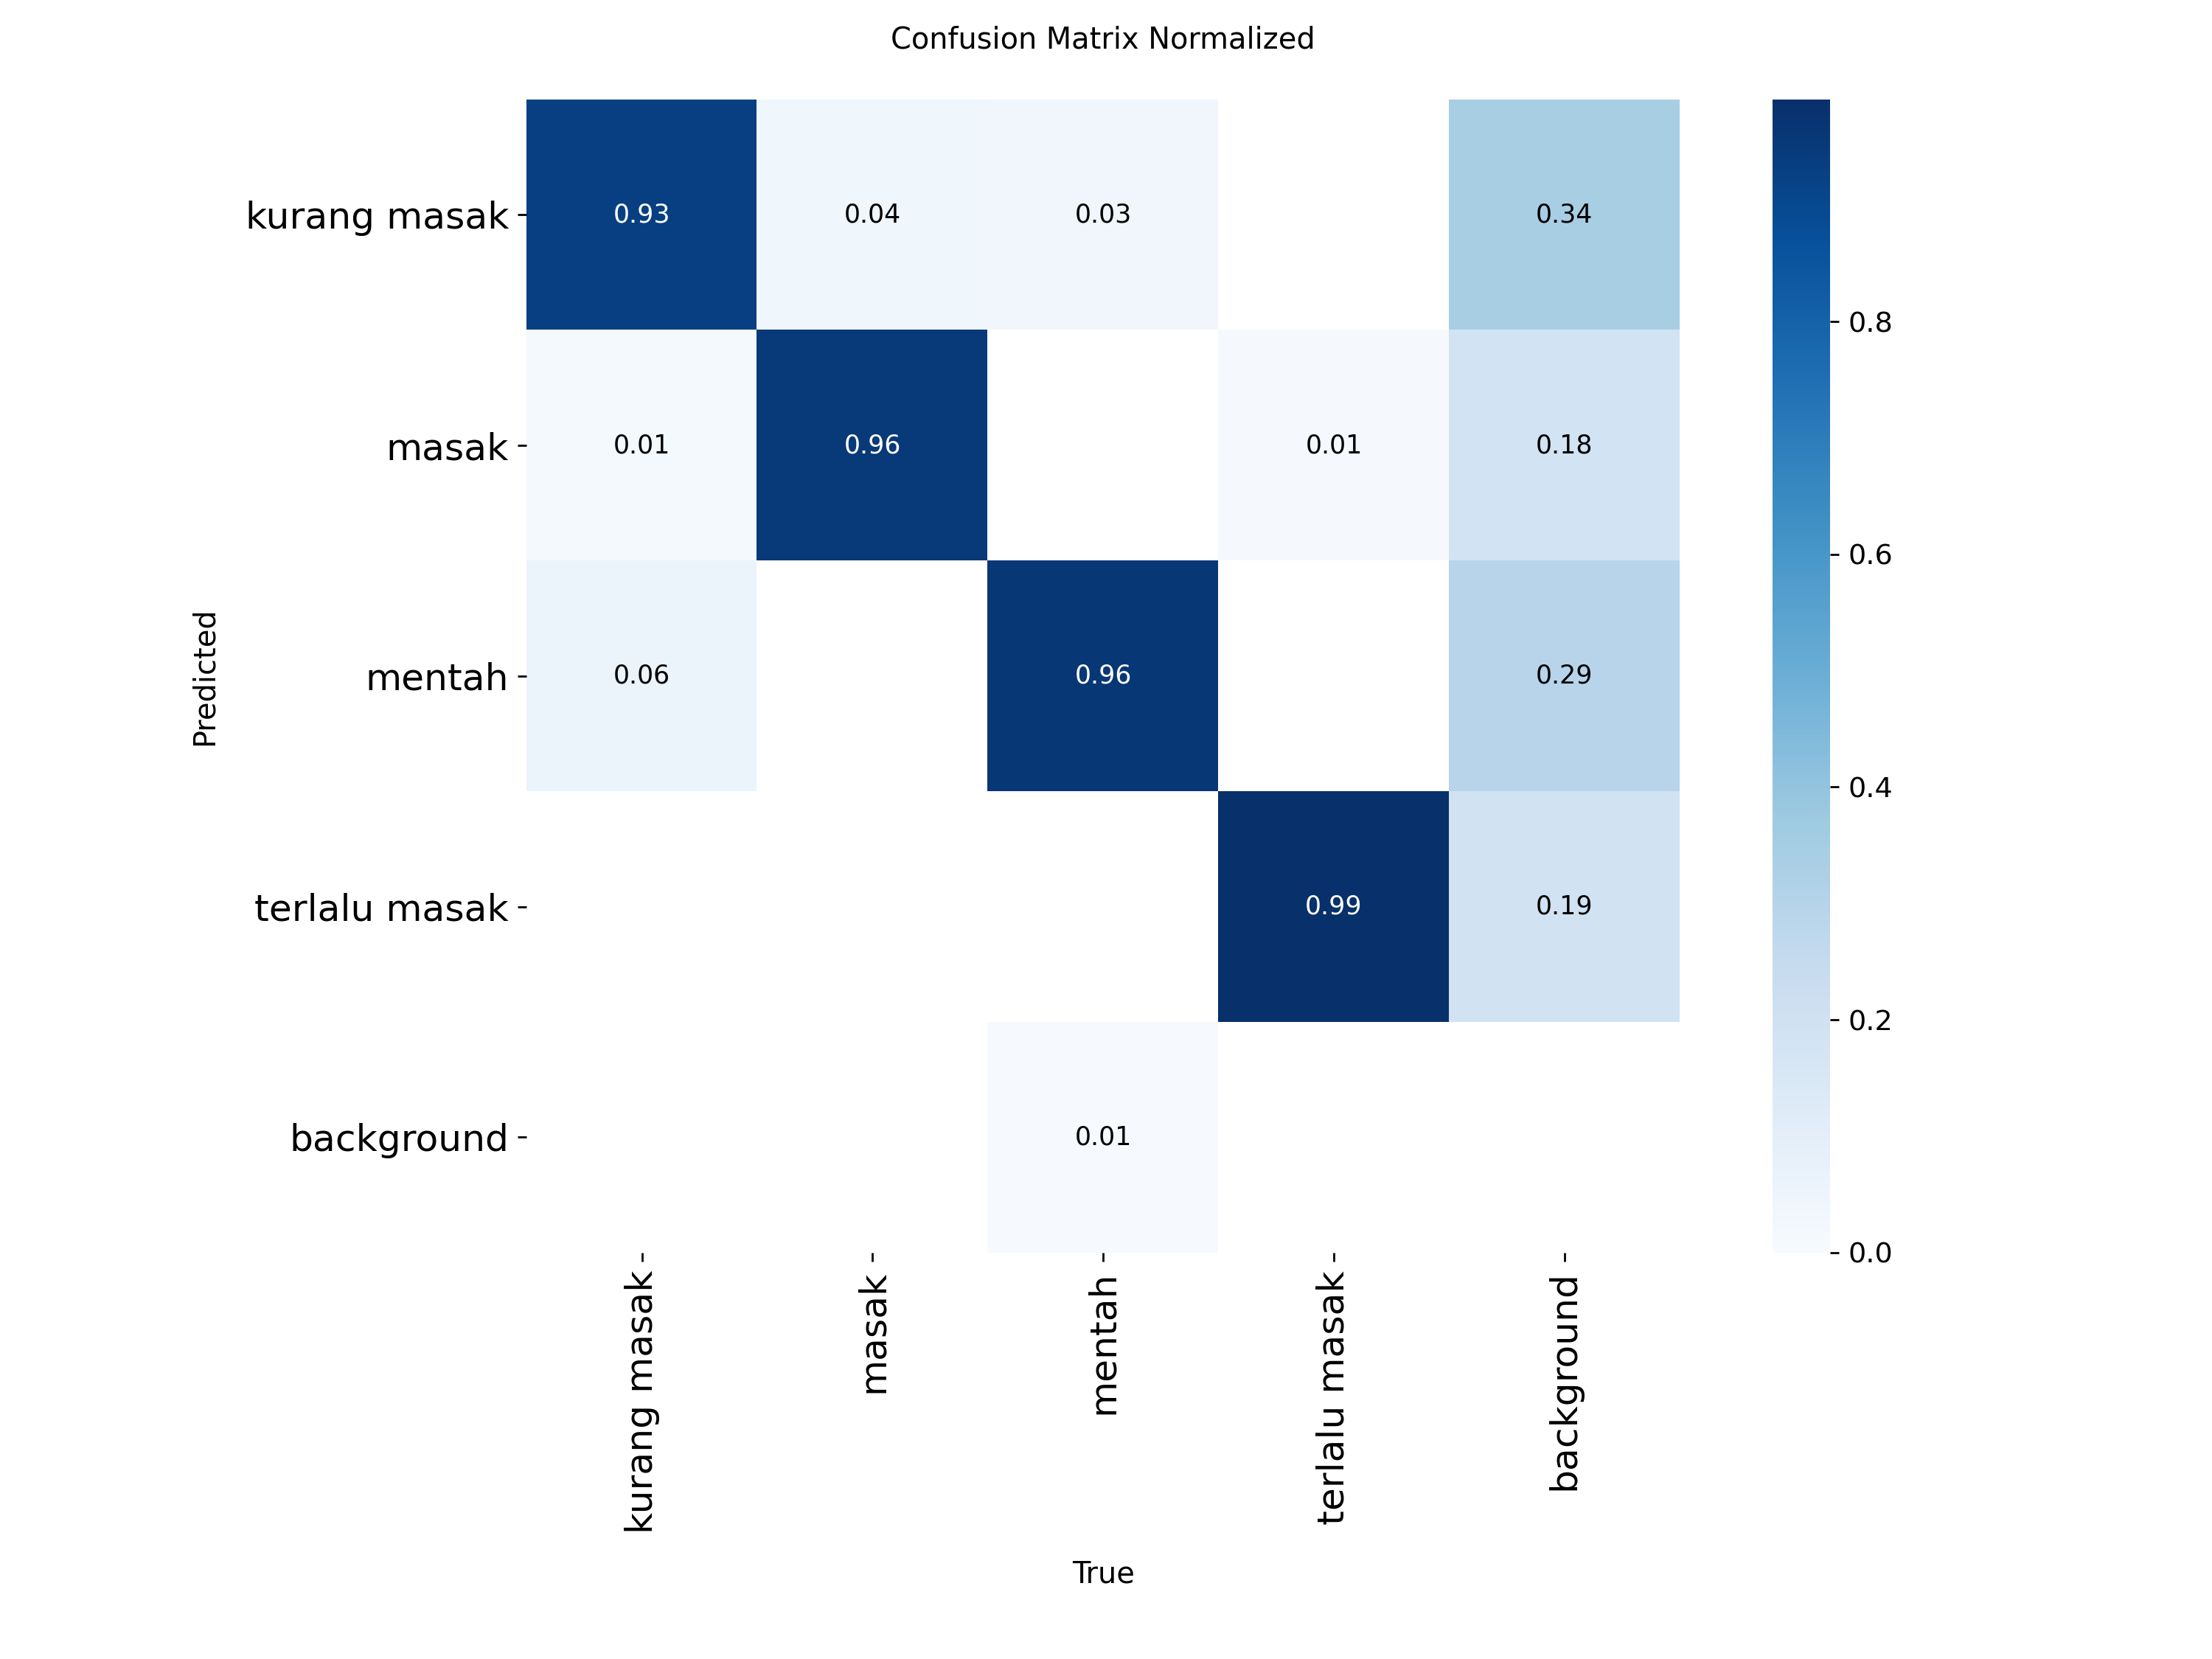

In [19]:
from IPython.display import Image, display
test_dir = Path(OUT_DIR) / "finetuned_test"
for f in ["confusion_matrix_normalized.png", "PR_curve.png"]:
    p = test_dir / f
    if p.exists():
        print(f); display(Image(filename=str(p), width=700))

**Cara membaca output:** bandingkan baris `baseline` dan `finetuned` pada split test. Selisih kecil (misalnya ±0,01) wajar dan jangan dilebih-lebihkan; yang penting dijelaskan apa adanya. Matriks konfusi menunjukkan kelas mana yang tertukar dan seberapa sering terjadi kotak pada area tanpa objek (kolom *background*).

## Tahap 12 — Evaluasi COCO (pycocotools) agar Setara dengan Faster R-CNN

Ultralytics dan pycocotools menghitung mAP dengan implementasi yang sedikit berbeda. Supaya perbandingan dengan Faster R-CNN adil, YOLO dievaluasi ulang dengan **pycocotools pada `instances_test.json` yang sama**, memakai ambang skor 0,05 dan NMS IoU 0,5 (bawaan torchvision), maksimum 100 deteksi per gambar. Kategori COCO 1–4 dipakai sesuai mapping di Tahap 5.

Sel ini dilewati otomatis jika `COCO_TEST_JSON` belum diisi.

In [20]:
COCO_CONF, COCO_NMS_IOU, COCO_MAX_DET = 0.05, 0.5, 100

def coco_eval_yolo(weights, tag):
    from pycocotools.coco import COCO
    from pycocotools.cocoeval import COCOeval
    gt = COCO(str(COCO_TEST_JSON))
    stem_to_id = {Path(info["file_name"]).stem: i for i, info in gt.imgs.items()}
    test_imgs = image_maps["test"]
    missing = [s for s in stem_to_id if s not in test_imgs]
    assert not missing, f"{len(missing)} gambar di JSON tidak ada di folder test. Contoh: {missing[:3]}"

    m = YOLO(str(weights))
    names = list(stem_to_id)
    dets = []
    for i in range(0, len(names), 32):
        chunk = names[i:i + 32]
        preds = m.predict([str(test_imgs[s]) for s in chunk], imgsz=IMGSZ, conf=COCO_CONF,
                          iou=COCO_NMS_IOU, max_det=COCO_MAX_DET, verbose=False,
                          device=0 if DEVICE == "cuda" else "cpu")
        for s, r in zip(chunk, preds):
            for b in r.boxes:
                x1, y1, x2, y2 = b.xyxy[0].tolist()
                dets.append({"image_id": stem_to_id[s], "category_id": int(b.cls) + 1,
                             "bbox": [x1, y1, x2 - x1, y2 - y1], "score": float(b.conf)})
    if not dets:
        return None
    ev = COCOeval(gt, gt.loadRes(dets), "bbox")
    ev.params.catIds = [1, 2, 3, 4]
    ev.evaluate(); ev.accumulate(); ev.summarize()
    return {"mAP@[0.50:0.95]": round(float(ev.stats[0]), 4),
            "mAP@0.50": round(float(ev.stats[1]), 4),
            "mAP@0.75": round(float(ev.stats[2]), 4)}

COCO_RESULTS = {}
if COCO_TEST_JSON:
    COCO_RESULTS["baseline"] = coco_eval_yolo(BASE_BEST, "baseline")
    COCO_RESULTS["finetuned"] = coco_eval_yolo(FT_BEST, "finetuned")
    display(pd.DataFrame(COCO_RESULTS).T)
else:
    print("COCO_TEST_JSON belum diisi, evaluasi pycocotools dilewati.")

loading annotations into memory...
Done (t=0.19s)
creating index...
index created!
Loading and preparing results...
DONE (t=0.00s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=0.33s).
Accumulating evaluation results...
DONE (t=0.06s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.739
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.943
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.897
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.740
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.446
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.792
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDet

,mAP@[0.50:0.95],mAP@0.50,mAP@0.75
baseline,0.7388,0.9434,0.8967
finetuned,0.7487,0.9528,0.9070


In [21]:
# Tabel pembanding lintas model (split test, metrik COCO).
# Angka Faster R-CNN diambil dari notebook Faster R-CNN temanmu; perbarui jika berubah.
REFERENSI_FRCNN = {
    "Faster R-CNN baseline":   {"mAP@[0.50:0.95]": 0.7157, "mAP@0.50": 0.9562, "mAP@0.75": 0.8791},
    "Faster R-CNN fine-tuned": {"mAP@[0.50:0.95]": 0.7200, "mAP@0.50": 0.9565, "mAP@0.75": 0.8910},
}
if COCO_RESULTS and all(COCO_RESULTS.values()):
    banding = {"YOLOv11 baseline": COCO_RESULTS["baseline"], "YOLOv11 fine-tuned": COCO_RESULTS["finetuned"], **REFERENSI_FRCNN}
    display(pd.DataFrame(banding).T)
else:
    print("Isi COCO_TEST_JSON dan jalankan sel sebelumnya untuk melihat tabel pembanding ini.")

,mAP@[0.50:0.95],mAP@0.50,mAP@0.75
YOLOv11 baseline,0.7388,0.9434,0.8967
YOLOv11 fine-tuned,0.7487,0.9528,0.9070
Faster R-CNN baseline,0.7157,0.9562,0.8791
Faster R-CNN fine-tuned,0.7200,0.9565,0.8910


**Cara membaca output:** keempat baris memakai definisi metrik yang sama (COCO, test set yang sama), sehingga bisa dibandingkan langsung. Perbedaan kecil antar model tidak otomatis berarti satu model lebih baik; bahas bersama kecepatan, ukuran, dan jenis kesalahan (Tahap 13 dan 15).

## Tahap 13 — Analisis Error pada Data Uji

Definisi disamakan dengan analisis error Faster R-CNN: model fine-tuned diaudit pada data uji dengan **IoU ≥ 0,50** dan **ambang skor 0,50**.

- **Tandan terlewat:** objek asli (GT) tidak punya prediksi apa pun yang menutupinya pada IoU ≥ 0,50.
- **Salah kelas:** ada prediksi yang menutupi GT (IoU ≥ 0,50), tetapi kelasnya berbeda.
- **Box ganda:** lebih dari satu prediksi kelas yang sama menutupi satu GT; satu dihitung sebagai pasangan utama, sisanya error.
- **Kotak tanpa objek:** prediksi yang tidak menutupi GT mana pun (*false positive*).

Kolom `occlusion_review` sengaja dikosongkan untuk diisi manual setelah melihat gambar, karena tingkat keterhalangan daun tidak bisa disimpulkan dari anotasi kotak saja.

In [22]:
ERR_IOU, ERR_SCORE = 0.50, 0.50

def box_iou(a, b):
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0.0, x2 - x1) * max(0.0, y2 - y1)
    union = max(0.0, a[2] - a[0]) * max(0.0, a[3] - a[1]) + max(0.0, b[2] - b[0]) * max(0.0, b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0

def analyze_image(gt, preds, iou_thr=0.5):
    # gt: [(kelas, (x1,y1,x2,y2))]; preds: [(kelas, skor, (x1,y1,x2,y2))]
    errors, used = [], set()
    for gc, gb in gt:
        ious = [box_iou(gb, pb) for _, _, pb in preds]
        same = [i for i, (pc, _, _) in enumerate(preds) if pc == gc and ious[i] >= iou_thr]
        if same:
            used.update(same)
            for i in same[1:]:
                errors.append({"jenis": "box ganda", "gt": gc, "pred": gc, "iou": ious[i], "skor": preds[i][1], "gt_box": gb})
            continue
        other = [i for i, (pc, _, _) in enumerate(preds) if pc != gc and ious[i] >= iou_thr]
        if other:
            i = max(other, key=lambda k: ious[k])
            used.add(i)
            errors.append({"jenis": "salah kelas", "gt": gc, "pred": preds[i][0], "iou": ious[i], "skor": preds[i][1], "gt_box": gb})
        else:
            errors.append({"jenis": "tandan terlewat", "gt": gc, "pred": None, "iou": 0.0, "skor": None, "gt_box": gb})
    for i, (pc, ps, pb) in enumerate(preds):
        if i in used:
            continue
        if all(box_iou(pb, gb) < iou_thr for _, gb in gt):
            errors.append({"jenis": "kotak tanpa objek", "gt": None, "pred": pc, "iou": 0.0, "skor": ps, "gt_box": None})
    return errors

def read_gt(label_path, W, H):
    gt = []
    for line in Path(label_path).read_text().splitlines():
        tok = line.split()
        if len(tok) != 5:
            continue
        c = int(float(tok[0])); x, y, w, h = map(float, tok[1:])
        gt.append((c, ((x - w / 2) * W, (y - h / 2) * H, (x + w / 2) * W, (y + h / 2) * H)))
    return gt

In [23]:
err_model = YOLO(str(FT_BEST))
test_names = sorted(image_maps["test"])
all_errors, n_gt, per_image_cases = [], 0, []

for i in range(0, len(test_names), 32):
    chunk = test_names[i:i + 32]
    preds = err_model.predict([str(image_maps["test"][s]) for s in chunk], imgsz=IMGSZ, conf=ERR_SCORE,
                              iou=COCO_NMS_IOU, max_det=COCO_MAX_DET, verbose=False,
                              device=0 if DEVICE == "cuda" else "cpu")
    for s, r in zip(chunk, preds):
        H, W = r.orig_shape
        gt = read_gt(DATA_ROOT / "test" / "labels" / f"{s}.txt", W, H)
        n_gt += len(gt)
        pr = [(int(b.cls), float(b.conf), tuple(b.xyxy[0].tolist())) for b in r.boxes]
        errs = analyze_image(gt, pr, ERR_IOU)
        for e in errs:
            e["file"] = image_maps["test"][s].name
            e["occlusion_review"] = ""
        all_errors.extend(errs)
        if errs:
            per_image_cases.append((s, gt, pr, errs))

err_df = pd.DataFrame(all_errors)
if err_df.empty:
    print("Tidak ada error pada ambang ini.")
else:
    err_df["gt"] = err_df["gt"].map(lambda c: CLASS_NAMES.get(c) if pd.notna(c) else None)
    err_df["pred"] = err_df["pred"].map(lambda c: CLASS_NAMES.get(c) if pd.notna(c) else None)
    ringkasan_err = err_df["jenis"].value_counts().rename("jumlah").to_frame()
    ringkasan_err["% dari total GT"] = (ringkasan_err["jumlah"] / n_gt * 100).round(2)
    print(f"Total tandan (GT) pada test: {n_gt}")
    display(ringkasan_err)
    sk = err_df[err_df["jenis"] == "salah kelas"]
    if len(sk):
        print("Pasangan salah kelas (baris = kelas asli, kolom = kelas prediksi):")
        display(pd.crosstab(sk["gt"], sk["pred"]))
    ERR_DIR = Path(OUT_DIR) / "error_analysis"
    ERR_DIR.mkdir(exist_ok=True)
    err_df.drop(columns=["gt_box"]).to_csv(ERR_DIR / "daftar_error_test.csv", index=False)
    ringkasan_err.to_csv(ERR_DIR / "ringkasan_error_test.csv")
    print("Tersimpan di:", ERR_DIR)

Total tandan (GT) pada test: 1355


,jumlah,% dari total GT
jenis,,
kotak tanpa objek,74,5.46
salah kelas,40,2.95
tandan terlewat,36,2.66


Pasangan salah kelas (baris = kelas asli, kolom = kelas prediksi):


pred,kurang masak,masak,mentah,terlalu masak
gt,,,,
kurang masak,0,2,14,0
masak,8,0,1,1
mentah,12,0,0,0
terlalu masak,0,2,0,0


Tersimpan di: /kaggle/working/FGD_Sawit_YOLOv11/error_analysis


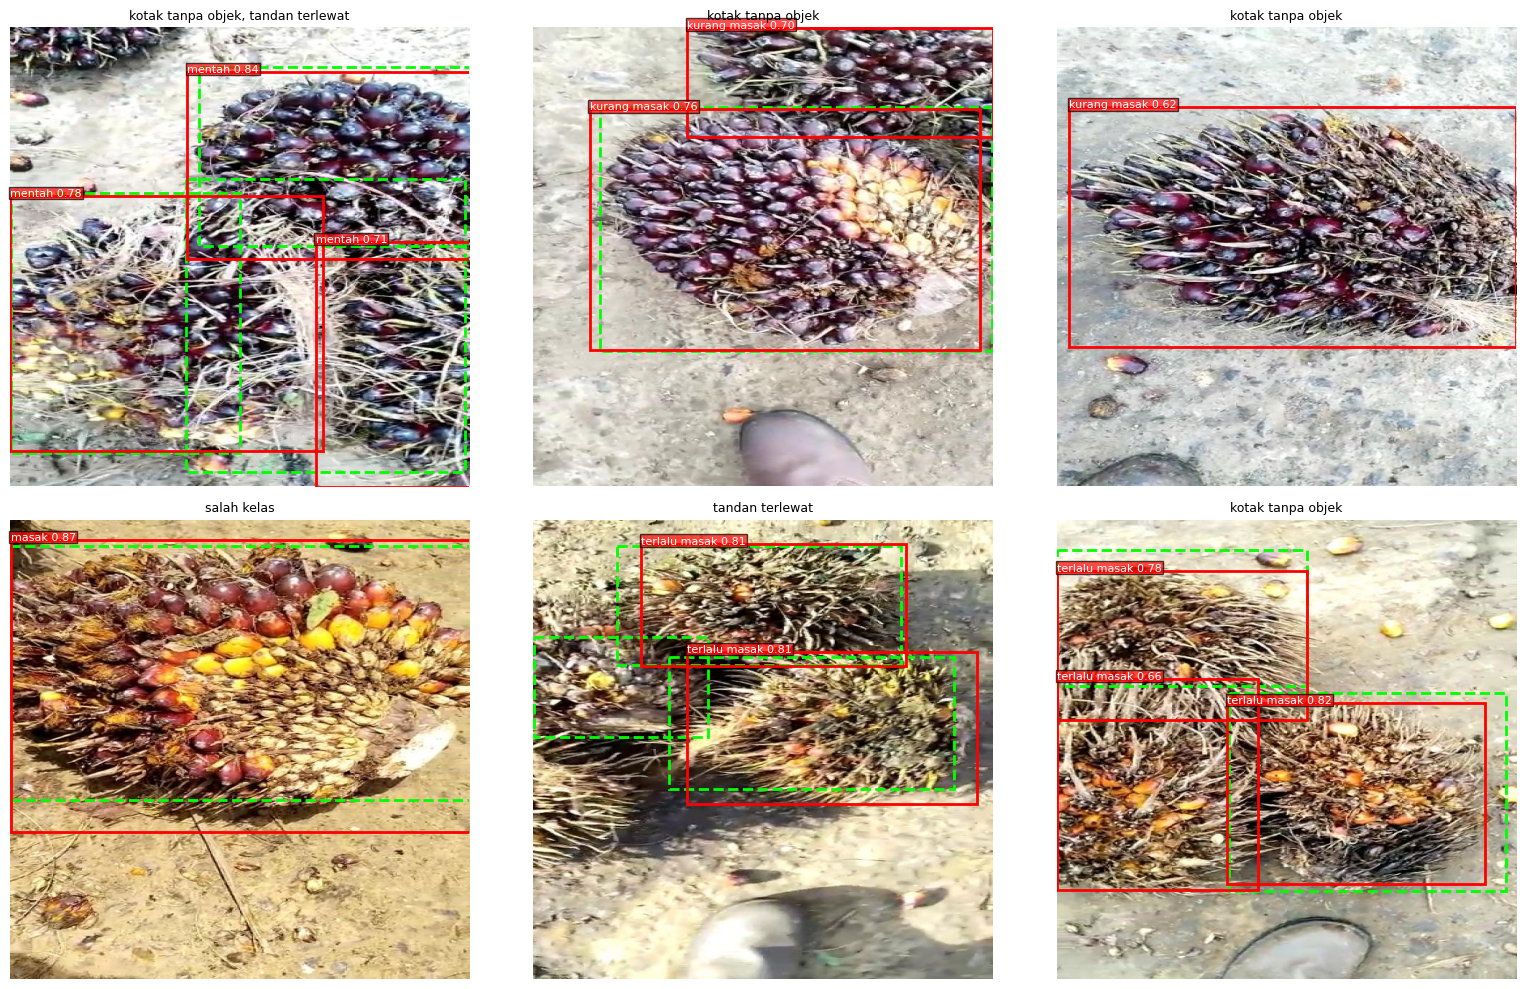

In [24]:
# Contoh visual error: kotak hijau putus-putus = GT, kotak berwarna = prediksi
import matplotlib.patches as patches
from PIL import Image as PILImage

if per_image_cases:
    random.seed(SEED)
    sample = random.sample(per_image_cases, min(6, len(per_image_cases)))
    fig, axes = plt.subplots(2, 3, figsize=(16, 10))
    for ax, (s, gt, pr, errs) in zip(axes.flat, sample):
        ax.imshow(PILImage.open(image_maps["test"][s]).convert("RGB")); ax.axis("off")
        for c, b in gt:
            ax.add_patch(patches.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec="lime", lw=2, ls="--"))
        for c, sc, b in pr:
            ax.add_patch(patches.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec="red", lw=2))
            ax.text(b[0], b[1], f"{CLASS_NAMES[c]} {sc:.2f}", color="white", fontsize=8, bbox=dict(fc="red", alpha=0.7, pad=1))
        ax.set_title(", ".join(sorted({e["jenis"] for e in errs})), fontsize=9)
    plt.tight_layout(); plt.show()

**Cara membaca output:** lihat jenis error yang dominan. Jika `salah kelas` dominan, masalahnya ada di pembedaan tingkat kematangan (kemungkinan kemiripan visual antar kelas atau konsistensi anotasi dataset publik). Jika `kotak tanpa objek` dominan, model terlalu sering mendeteksi area yang bukan tandan. Bawa contoh visual ini ke pakar untuk dinilai.

## Tahap 14 — Penyimpanan Model Akhir dan Ringkasan Artefak

Model disalin ke folder `final_models` dengan nama yang sama dengan yang dipakai aplikasi Streamlit (`yolo11_baseline.pt`, `yolo11_finetuned.pt`). Ringkasan metrik disimpan dalam satu JSON yang bisa digabung ke `metrics.json` aplikasi.

In [25]:
def model_complexity(weights):
    m = YOLO(str(weights))
    try:
        info = m.info(verbose=True)   # (layers, parameters, gradients, GFLOPs)
        return int(info[1]), round(float(info[3]), 1)
    except Exception:
        return int(sum(p.numel() for p in m.model.parameters())), None

FINAL_DIR = Path(OUT_DIR) / "final_models"
FINAL_DIR.mkdir(exist_ok=True)
shutil.copy(BASE_BEST, FINAL_DIR / "yolo11_baseline.pt")
shutil.copy(FT_BEST, FINAL_DIR / "yolo11_finetuned.pt")

def paket_metrik(name, key):
    t = RESULTS[name]["test"]
    params, gflops = model_complexity(FINAL_DIR / key)
    sec = TRAIN_SECONDS.get(name)
    return {
        "precision": t["precision"], "recall": t["recall"],
        "map50": t["mAP@0.5"], "map50_95": t["mAP@0.5:0.95"],
        "coco": COCO_RESULTS.get(name),
        "per_class": t["per_class"].to_dict(orient="records"),
        "params": params, "gflops": gflops,
        "train_hours": round(sec / 3600, 2) if sec else None,
        "train_gpu": GPU_NAME,
        "ukuran_file_mb": round(os.path.getsize(FINAL_DIR / key) / 1e6, 1),
    }

ringkasan = {
    "model_dasar": MODEL_NAME, "imgsz": IMGSZ, "batch": BATCH, "seed": SEED,
    "baseline_cfg": BASELINE, "finetune_cfg": FINETUNE,
    "epoch_terbaik_baseline": base_best_epoch, "epoch_terbaik_finetune": ft_best_epoch,
    "ultralytics": ultralytics.__version__, "torch": torch.__version__,
    "augmentasi": "default Ultralytics (mosaic, flip, HSV, dll), hanya pada train",
    "evaluasi_coco": {"conf": COCO_CONF, "nms_iou": COCO_NMS_IOU, "max_det": COCO_MAX_DET},
    "yolo11_baseline": paket_metrik("baseline", "yolo11_baseline.pt"),
    "yolo11_finetuned": paket_metrik("finetuned", "yolo11_finetuned.pt"),
    "dibuat": datetime.datetime.now().isoformat(timespec="seconds"),
}
with open(Path(OUT_DIR) / "ringkasan_yolov11.json", "w", encoding="utf-8") as f:
    json.dump(ringkasan, f, ensure_ascii=False, indent=2)

tabel.to_csv(Path(OUT_DIR) / "metrik_ringkasan.csv", index=False)
print("Tersimpan di :", OUT_DIR)
print("Model akhir  :", sorted(p.name for p in FINAL_DIR.iterdir()))

YOLO11s summary: 181 layers, 9,429,340 parameters, 0 gradients, 21.7 GFLOPs
YOLO11s summary: 181 layers, 9,429,340 parameters, 0 gradients, 21.7 GFLOPs
Tersimpan di : /kaggle/working/FGD_Sawit_YOLOv11
Model akhir  : ['yolo11_baseline.pt', 'yolo11_finetuned.pt']


## Tahap 15 — Penggunaan Komputasi (CPU vs GPU)

Untuk deployment, yang diukur adalah latensi **satu gambar per permintaan** (termasuk baca gambar dan *postprocess*), pemakaian memori, dan ukuran file. CPU Colab hanya 2 inti, jadi hasilnya mendekati hosting gratis tetapi bukan server sebenarnya. Jalankan sel yang sama untuk Faster R-CNN agar adil.

In [26]:
import psutil

BENCH_IMGS = [image_maps["test"][s] for s in sorted(image_maps["test"])[:50]]

def benchmark(weights, device, label):
    m = YOLO(str(weights))
    for p in BENCH_IMGS[:5]:   # pemanasan
        m.predict(str(p), imgsz=IMGSZ, device=device, verbose=False)
    if device != "cpu":
        torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    waktu = []
    for p in BENCH_IMGS:
        t = time.perf_counter()
        m.predict(str(p), imgsz=IMGSZ, device=device, verbose=False)
        if device != "cpu":
            torch.cuda.synchronize()
        waktu.append((time.perf_counter() - t) * 1000)
    s = pd.Series(waktu)
    mem = torch.cuda.max_memory_allocated() / 1e6 if device != "cpu" else psutil.Process().memory_info().rss / 1e6
    return {"model": label, "device": "GPU" if device != "cpu" else "CPU",
            "rata2_ms": round(s.mean(), 1), "median_ms": round(s.median(), 1),
            "p95_ms": round(s.quantile(0.95), 1), "FPS": round(1000 / s.mean(), 1), "memori_MB": round(mem)}

bench = []
for key, label in [("yolo11_baseline.pt", "YOLOv11 baseline"), ("yolo11_finetuned.pt", "YOLOv11 fine-tuned")]:
    bench.append(benchmark(FINAL_DIR / key, "cpu", label))
    if DEVICE == "cuda":
        bench.append(benchmark(FINAL_DIR / key, 0, label))
display(pd.DataFrame(bench))

,model,device,rata2_ms,median_ms,p95_ms,FPS,memori_MB
0,YOLOv11 baseline,CPU,183.8,181.1,198.9,5.4,4973
1,YOLOv11 baseline,GPU,14.2,13.3,17.5,70.3,684
2,YOLOv11 fine-tuned,CPU,180.7,180.7,187.8,5.5,4997
3,YOLOv11 fine-tuned,GPU,14.4,13.5,20.7,69.6,718


## Tahap 16 — Uji Coba dengan Gambar Sendiri

Secara default notebook memakai 3 gambar acak dari data test. Untuk foto sendiri: klik **Add Input → Upload**, buat dataset dari foto itu, lalu isi `UPLOAD_PATHS` dengan path-nya (`/kaggle/input/...`). Coba kondisi berbeda dan catat kasus yang meleset sebagai bahan pembahasan keterbatasan.

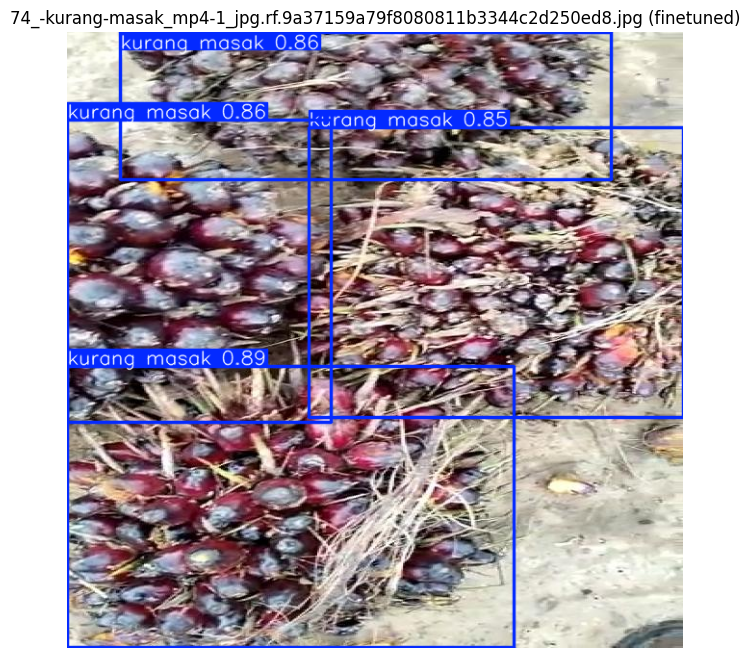

- kurang masak: 89%
- kurang masak: 86%
- kurang masak: 86%
- kurang masak: 85%



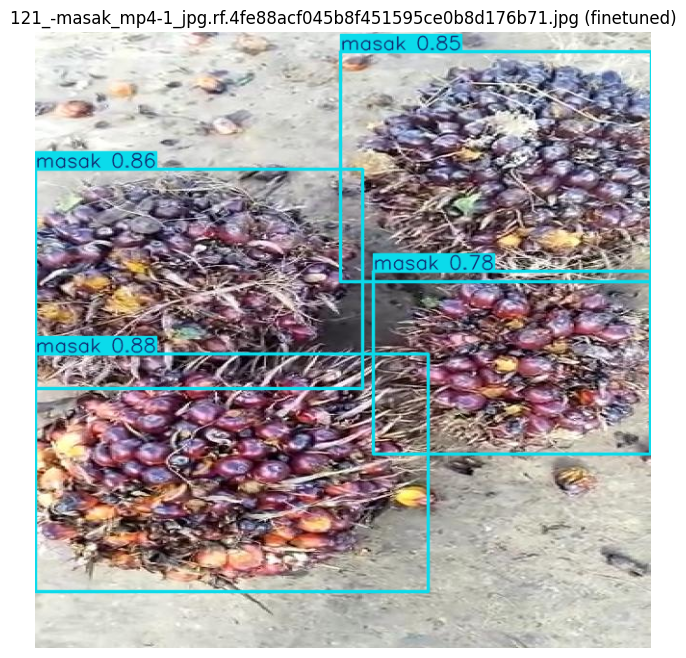

- masak: 88%
- masak: 86%
- masak: 85%
- masak: 78%



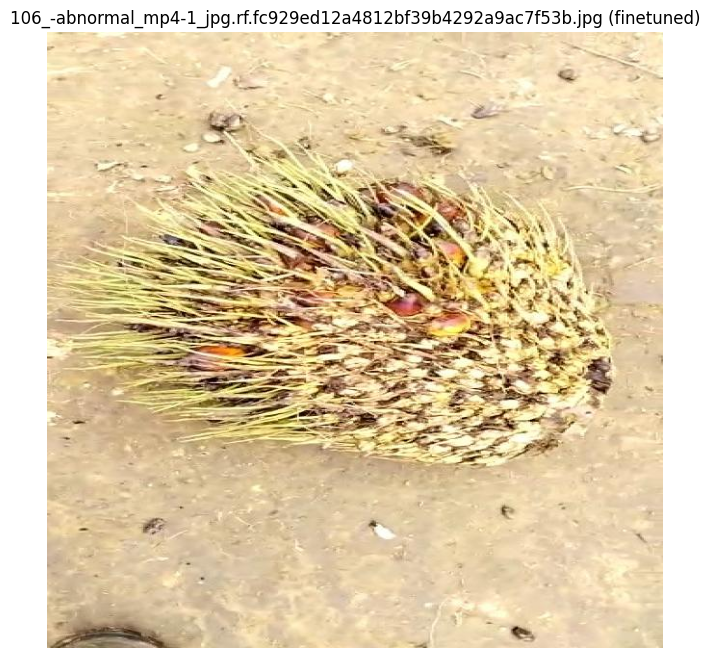

Tidak ada buah sawit terdeteksi.



In [27]:
import cv2, random

PILIH = "finetuned"   # "baseline" atau "finetuned"
CONF = 0.25           # naikkan kalau terlalu banyak kotak salah, turunkan kalau ada yang terlewat

# Isi dengan path foto sendiri (lihat catatan di bawah), atau kosongkan untuk contoh acak dari data test
UPLOAD_PATHS = []     # contoh: ["/kaggle/input/foto-saya/tandan1.jpg"]
if not UPLOAD_PATHS:
    random.seed(SEED)
    UPLOAD_PATHS = [str(p) for p in random.sample(sorted(image_maps["test"].values()), 3)]

demo_model = YOLO(str(FINAL_DIR / f"yolo11_{PILIH}.pt"))
for nama_file in UPLOAD_PATHS:
    hasil = demo_model.predict(nama_file, conf=CONF, imgsz=IMGSZ, verbose=False)[0]
    plt.figure(figsize=(8, 8))
    plt.imshow(cv2.cvtColor(hasil.plot(), cv2.COLOR_BGR2RGB))
    plt.title(f"{Path(nama_file).name} ({PILIH})"); plt.axis("off"); plt.show()
    if len(hasil.boxes) == 0:
        print("Tidak ada buah sawit terdeteksi.\n")
    else:
        for kotak in hasil.boxes:
            print(f"- {demo_model.names[int(kotak.cls)]}: {float(kotak.conf):.0%}")
        print()

## Artefak Hasil

Semua artefak tersimpan di Kaggle Input pada folder `OUT_DIR`:

| Artefak | Kegunaan |
|---|---|
| `final_models/yolo11_baseline.pt`, `yolo11_finetuned.pt` | Model untuk aplikasi Streamlit |
| `ringkasan_yolov11.json` | Metrik, hyperparameter, versi library, kompleksitas model (untuk laporan dan `metrics.json` aplikasi) |
| `metrik_ringkasan.csv` | Tabel val/test baseline dan fine-tuned |
| `error_analysis/` | Daftar dan ringkasan error di data uji |
| `yolo11s_baseline20/`, `yolo11s_finetune/` | Folder run lengkap (kurva, bobot, `results.csv`) |
| `yolo11s_sawit/` (jika ada) | Run lama 100 epoch; boleh dipakai sebagai referensi tambahan, bukan pengganti baseline 20 epoch |

**Catatan keterbatasan untuk pembahasan:** resize *stretch* 640×640 mengubah rasio aspek objek; data berasal dari frame video sehingga frame yang mirip dapat muncul di beberapa split; label poligon dikonversi menjadi bbox; definisi kelas mengikuti anotasi dataset publik dan belum divalidasi pakar lapangan.